# Exploratory Data Analysis (EDA)

## Project: Nassau Candy Distributor

### Objective
To explore sales, gross profit, cost, units, product performance,
division performance, geographical performance, customer performance,
shipping performance, time trends, and numerical relationships.

### Input Dataset
data/processed/Nassau_Candy_Feature_Engineered.csv

### Expected Tasks
04.01 to 04.40

### Data Integrity Rules
- Original CSV will not be modified.
- Original 18 columns will remain unchanged.
- No original rows will be deleted.
- Outliers will be analysed, not removed.
- Date anomalies will be investigated, not corrected.
- Division by zero will be handled safely.

In [5]:
# Import libraries and load the feature-engineered dataset for EDA

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r"C:\Users\hp\Nassau_Candy_Final_Submission")

INPUT_PATH = (
    PROJECT_ROOT / "data" / "processed"
    / "Nassau_Candy_Feature_Engineered.csv"
)

FIGURES_FOLDER = PROJECT_ROOT / "reports" / "figures"
PROCESSED_FOLDER = PROJECT_ROOT / "data" / "processed"
REPORT_FOLDER = PROJECT_ROOT / "reports"

FIGURES_FOLDER.mkdir(parents=True, exist_ok=True)
PROCESSED_FOLDER.mkdir(parents=True, exist_ok=True)
REPORT_FOLDER.mkdir(parents=True, exist_ok=True)

# Load the processed dataset
df_eda = pd.read_csv(INPUT_PATH)

# Convert separate helper date columns to datetime
df_eda["Order_Date_Parsed"] = pd.to_datetime(
    df_eda["Order_Date_Parsed"],
    errors="coerce"
)

df_eda["Ship_Date_Parsed"] = pd.to_datetime(
    df_eda["Ship_Date_Parsed"],
    errors="coerce"
)

# Ensure numerical columns have appropriate data types
numeric_columns = [
    "Sales",
    "Gross Profit",
    "Cost",
    "Units",
    "Lead_Time_Days",
    "Profit_Margin_Pct",
    "Sales_Per_Unit",
    "Cost_Per_Unit",
    "Profit_Per_Unit"
]

for column in numeric_columns:
    df_eda[column] = pd.to_numeric(
        df_eda[column],
        errors="coerce"
    )

# Preserve original column names for integrity verification
original_columns = [
    "Row ID",
    "Order ID",
    "Order Date",
    "Ship Date",
    "Ship Mode",
    "Customer ID",
    "Country/Region",
    "City",
    "State/Province",
    "Postal Code",
    "Division",
    "Region",
    "Product ID",
    "Product Name",
    "Sales",
    "Units",
    "Gross Profit",
    "Cost"
]

# Create a reusable chart-saving function
def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        FIGURES_FOLDER / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# Create reusable grouping function
def grouped_summary(group_column):
    return (
        df_eda.groupby(group_column, dropna=False)
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Gross_Profit=("Gross Profit", "sum"),
            Total_Cost=("Cost", "sum"),
            Total_Units=("Units", "sum"),
            Record_Count=("Row ID", "count")
        )
        .reset_index()
    )

# Calculate aggregate profit margin safely
def add_profit_margin(summary):
    summary["Profit_Margin_Pct"] = np.where(
        summary["Total_Sales"] != 0,
        summary["Total_Gross_Profit"]
        / summary["Total_Sales"] * 100,
        np.nan
    )
    return summary

print("Dataset loaded successfully.")
print("Dataset shape:", df_eda.shape)
print("Figure folder:", FIGURES_FOLDER)
print("Processed folder:", PROCESSED_FOLDER)
print("Reports folder:", REPORT_FOLDER)

display(df_eda.head())

Dataset loaded successfully.
Dataset shape: (10194, 34)
Figure folder: C:\Users\hp\Nassau_Candy_Final_Submission\reports\figures
Processed folder: C:\Users\hp\Nassau_Candy_Final_Submission\data\processed
Reports folder: C:\Users\hp\Nassau_Candy_Final_Submission\reports


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Order_Weekday,Ship_Year,Ship_Month,Profit_Margin_Pct,Sales_Per_Unit,Cost_Per_Unit,Profit_Per_Unit,Lead_Time_Category,Profit_Category,Sales_Category
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,...,Wednesday,2026,6,64.923077,3.25,1.14,2.11,Low,Low,Low
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,Thursday,2026,7,65.333333,3.75,1.30,2.45,Low,Low,Low
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,Thursday,2026,7,71.346705,3.49,1.00,2.49,Low,Medium,Medium
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,Thursday,2026,7,69.444444,3.60,1.10,2.50,Low,Medium,Medium
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,Friday,2026,7,65.333333,3.75,1.30,2.45,Low,Medium,Medium


In [7]:
# Verify dataset structure and original columns before starting EDA

print("Dataset dimensions:", df_eda.shape)

print("\nOriginal columns present:")
for column in original_columns:
    print(column, ":", column in df_eda.columns)

print("\nMissing values in dataset:")
display(df_eda.isnull().sum().to_frame("Missing_Count"))

print("\nNumerical summary:")
display(df_eda[numeric_columns].describe())

assert len(df_eda) == 10194
assert len(df_eda.columns) == 34
assert all(column in df_eda.columns for column in original_columns)

print("\nSUCCESS: EDA dataset structure verified.")

Dataset dimensions: (10194, 34)

Original columns present:
Row ID : True
Order ID : True
Order Date : True
Ship Date : True
Ship Mode : True
Customer ID : True
Country/Region : True
City : True
State/Province : True
Postal Code : True
Division : True
Region : True
Product ID : True
Product Name : True
Sales : True
Units : True
Gross Profit : True
Cost : True

Missing values in dataset:


,Missing_Count
Row ID,0
Order ID,0
Order Date,0
Ship Date,0
Ship Mode,0
Customer ID,0
Country/Region,0
City,0
State/Province,0
Postal Code,0



Numerical summary:


,Sales,Gross Profit,Cost,Units,Lead_Time_Days,Profit_Margin_Pct,Sales_Per_Unit,Cost_Per_Unit,Profit_Per_Unit
count,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,13.908537,9.166451,4.742087,3.791838,1320.841868,66.514045,3.654257,1.241719,2.412539
std,11.341020,6.643740,5.061647,2.228317,262.444892,6.721012,1.611875,0.871623,0.806007
min,1.250000,0.250000,0.600000,1.000000,904.000000,7.692308,1.250000,0.600000,0.250000
25%,7.200000,4.900000,2.400000,2.000000,1271.000000,65.333333,3.490000,1.100000,2.400000
50%,10.800000,7.470000,3.600000,3.000000,1274.000000,66.666667,3.600000,1.140000,2.450000
75%,18.000000,12.250000,5.700000,5.000000,1638.000000,69.444444,3.600000,1.200000,2.490000
max,260.000000,130.000000,130.000000,14.000000,1642.000000,80.000000,20.000000,10.000000,10.000000



SUCCESS: EDA dataset structure verified.


In [9]:
# Prepare the EDA workspace without modifying original dataset columns

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_ROOT = Path(r"C:\Users\hp\Nassau_Candy_Final_Submission")

INPUT_PATH = (
    PROJECT_ROOT / "data" / "processed"
    / "Nassau_Candy_Feature_Engineered.csv"
)

FIGURES_FOLDER = PROJECT_ROOT / "reports" / "figures"
REPORT_FOLDER = PROJECT_ROOT / "reports"
PROCESSED_FOLDER = PROJECT_ROOT / "data" / "processed"

FIGURES_FOLDER.mkdir(parents=True, exist_ok=True)
REPORT_FOLDER.mkdir(parents=True, exist_ok=True)

df_eda = pd.read_csv(INPUT_PATH)

# Convert only the separate helper date columns
df_eda["Order_Date_Parsed"] = pd.to_datetime(
    df_eda["Order_Date_Parsed"], errors="coerce"
)
df_eda["Ship_Date_Parsed"] = pd.to_datetime(
    df_eda["Ship_Date_Parsed"], errors="coerce"
)

# Ensure analytical columns are numeric
numeric_columns = [
    "Sales", "Gross Profit", "Cost", "Units",
    "Lead_Time_Days", "Profit_Margin_Pct"
]

for column in numeric_columns:
    df_eda[column] = pd.to_numeric(df_eda[column], errors="coerce")

# Preserve the original 18 columns for final integrity checks
original_columns = [
    "Row ID", "Order ID", "Order Date", "Ship Date", "Ship Mode",
    "Customer ID", "Country/Region", "City", "State/Province",
    "Postal Code", "Division", "Region", "Product ID",
    "Product Name", "Sales", "Units", "Gross Profit", "Cost"
]

def save_chart(filename):
    plt.tight_layout()
    plt.savefig(
        FIGURES_FOLDER / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

def grouped_summary(group_column):
    return (
        df_eda.groupby(group_column, dropna=False)
        .agg(
            Total_Sales=("Sales", "sum"),
            Total_Gross_Profit=("Gross Profit", "sum"),
            Total_Cost=("Cost", "sum"),
            Total_Units=("Units", "sum"),
            Record_Count=("Row ID", "count")
        )
        .reset_index()
    )

def add_profit_margin(summary):
    summary["Profit_Margin_Pct"] = np.where(
        summary["Total_Sales"] != 0,
        summary["Total_Gross_Profit"] / summary["Total_Sales"] * 100,
        np.nan
    )
    return summary

print("EDA dataset loaded.")
print("Dataset shape:", df_eda.shape)
print("Original columns retained:", all(
    col in df_eda.columns for col in original_columns
))
display(df_eda.head())

EDA dataset loaded.
Dataset shape: (10194, 34)
Original columns retained: True


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,...,Order_Weekday,Ship_Year,Ship_Month,Profit_Margin_Pct,Sales_Per_Unit,Cost_Per_Unit,Profit_Per_Unit,Lead_Time_Category,Profit_Category,Sales_Category
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,...,Wednesday,2026,6,64.923077,3.25,1.14,2.11,Low,Low,Low
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,Thursday,2026,7,65.333333,3.75,1.30,2.45,Low,Low,Low
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,Thursday,2026,7,71.346705,3.49,1.00,2.49,Low,Medium,Medium
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,...,Thursday,2026,7,69.444444,3.60,1.10,2.50,Low,Medium,Medium
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,...,Friday,2026,7,65.333333,3.75,1.30,2.45,Low,Medium,Medium


In [11]:
# Calculate total sales

total_sales = df_eda["Sales"].sum()

print("Total Sales:", round(total_sales, 2))

Total Sales: 141783.63


In [13]:
# Calculate total gross profit

total_gross_profit = df_eda["Gross Profit"].sum()

print("Total Gross Profit:", round(total_gross_profit, 2))

Total Gross Profit: 93442.8


In [15]:
# Calculate total cost

total_cost = df_eda["Cost"].sum()

print("Total Cost:", round(total_cost, 2))

Total Cost: 48340.83


In [17]:
# Calculate total units sold

total_units = df_eda["Units"].sum()

print("Total Units Sold:", total_units)

Total Units Sold: 38654


In [19]:
# Calculate average sales per dataset row

average_sales = df_eda["Sales"].mean()

print("Average Sales per Row:", round(average_sales, 2))

Average Sales per Row: 13.91


In [21]:
# Calculate average gross profit per dataset row

average_gross_profit = df_eda["Gross Profit"].mean()

print("Average Gross Profit per Row:", round(average_gross_profit, 2))

Average Gross Profit per Row: 9.17


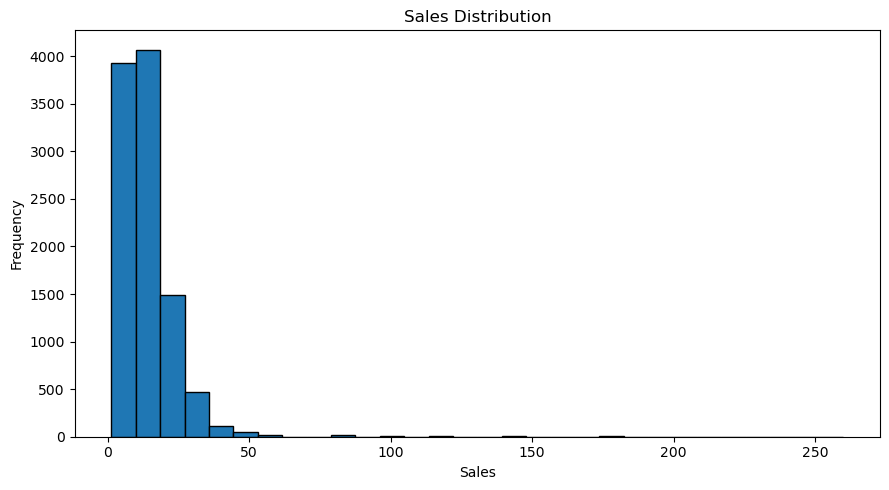

In [25]:
#Distribution analysis
#Visualise the distribution of sales

plt.figure(figsize=(9, 5))
plt.hist(df_eda["Sales"].dropna(), bins=30, edgecolor="black")
plt.title("Sales Distribution")
plt.xlabel("Sales")
plt.ylabel("Frequency")
save_chart("eda_07_sales_distribution.png")

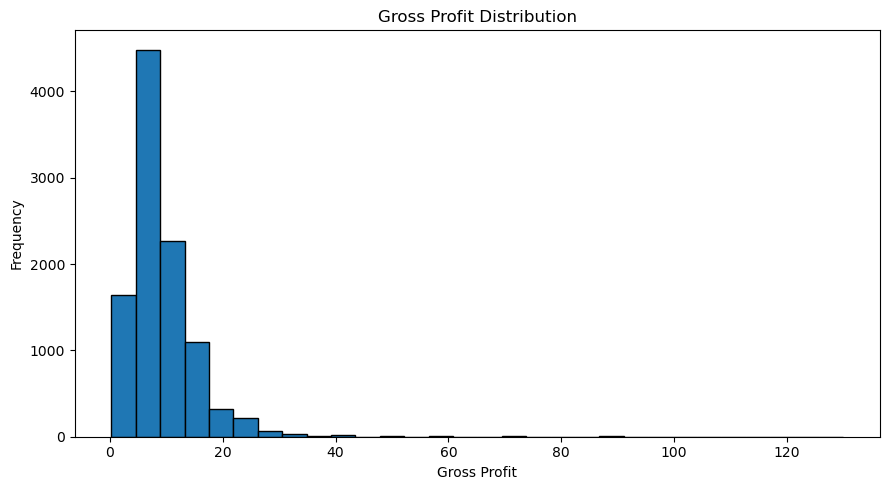

In [27]:
# Visualise the distribution of gross profit

plt.figure(figsize=(9, 5))
plt.hist(df_eda["Gross Profit"].dropna(), bins=30, edgecolor="black")
plt.title("Gross Profit Distribution")
plt.xlabel("Gross Profit")
plt.ylabel("Frequency")
save_chart("eda_08_profit_distribution.png")

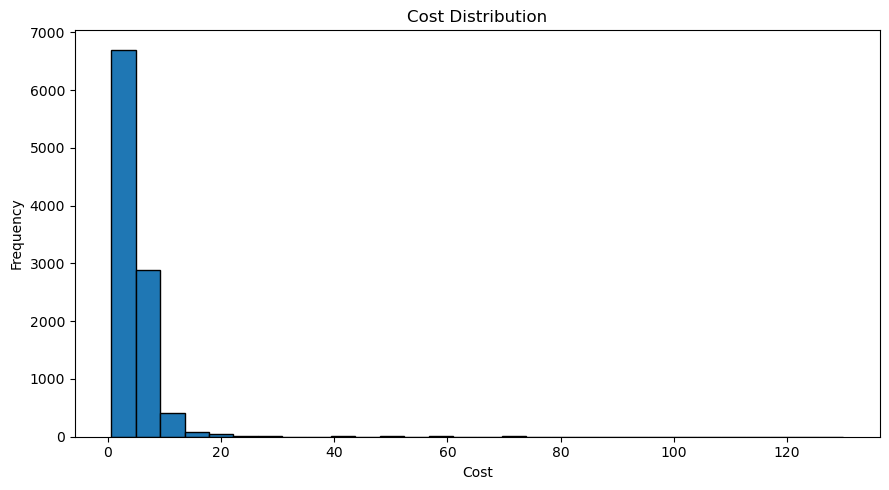

In [29]:
# Visualise the distribution of cost

plt.figure(figsize=(9, 5))
plt.hist(df_eda["Cost"].dropna(), bins=30, edgecolor="black")
plt.title("Cost Distribution")
plt.xlabel("Cost")
plt.ylabel("Frequency")
save_chart("eda_09_cost_distribution.png")

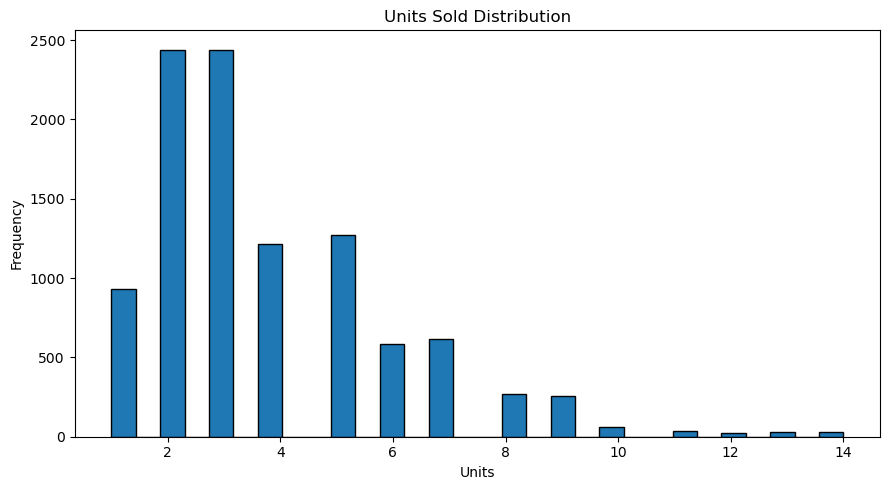

In [31]:
# Visualise the distribution of units sold

plt.figure(figsize=(9, 5))
plt.hist(df_eda["Units"].dropna(), bins=30, edgecolor="black")
plt.title("Units Sold Distribution")
plt.xlabel("Units")
plt.ylabel("Frequency")
save_chart("eda_10_units_distribution.png")

In [33]:
#Product analysis
#Product-wise sales

,Product Name,Total_Sales
12,Wonka Bar - Triple Dazzle Caramel,28485.00
13,Wonka Bar -Scrumdiddlyumptious,27874.80
10,Wonka Bar - Milk Chocolate,26867.75
9,Wonka Bar - Fudge Mallows,24890.40
11,Wonka Bar - Nutty Crunch Surprise,23574.95
6,Lickable Wallpaper,7860.00
4,Kazookles,1205.75
14,Wonka Gum,597.50
0,Everlasting Gobstopper,130.00
1,Fizzy Lifting Drinks,78.75


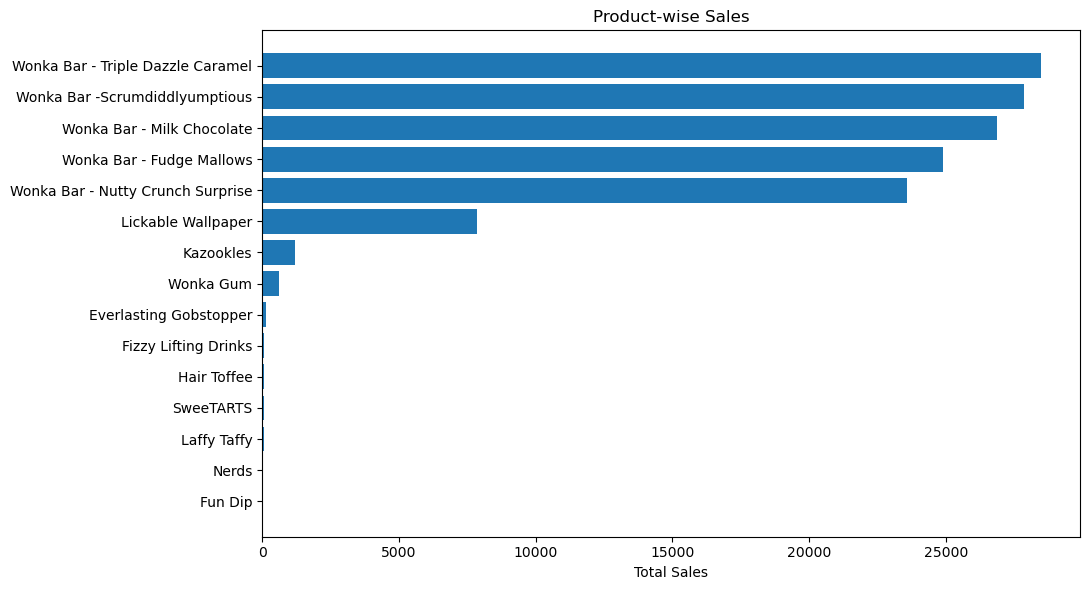

In [35]:
# Compare total sales across products

product_summary = add_profit_margin(
    grouped_summary("Product Name")
).sort_values("Total_Sales", ascending=False)

display(product_summary[["Product Name", "Total_Sales"]])

plt.figure(figsize=(11, 6))
plt.barh(
    product_summary.sort_values("Total_Sales")["Product Name"],
    product_summary.sort_values("Total_Sales")["Total_Sales"]
)
plt.title("Product-wise Sales")
plt.xlabel("Total Sales")
save_chart("eda_11_product_sales.png")

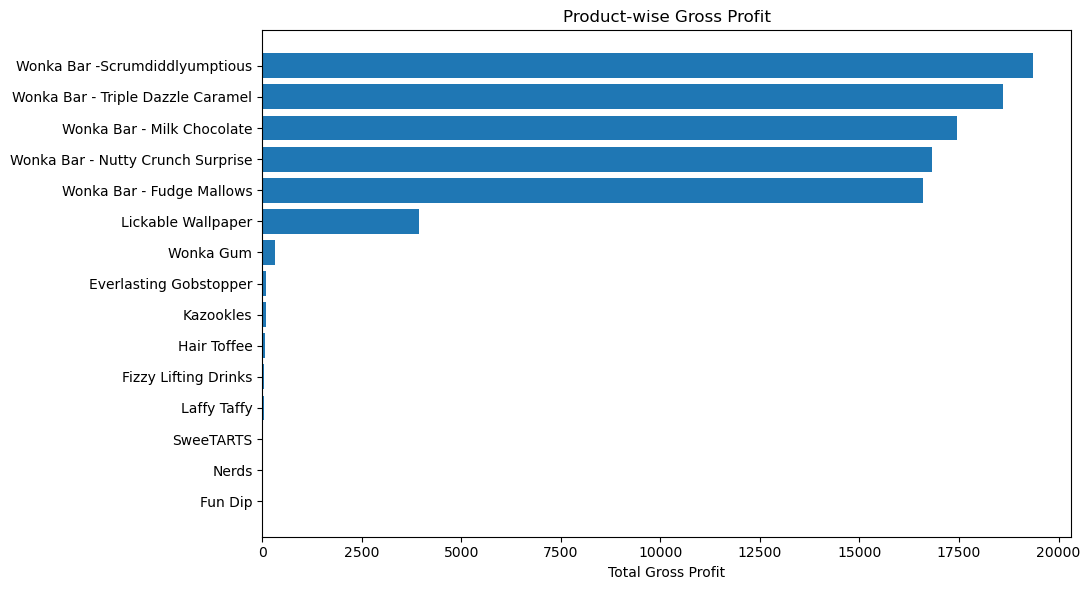

In [37]:
# Compare total gross profit across products

plt.figure(figsize=(11, 6))
data = product_summary.sort_values("Total_Gross_Profit")
plt.barh(data["Product Name"], data["Total_Gross_Profit"])
plt.title("Product-wise Gross Profit")
plt.xlabel("Total Gross Profit")
save_chart("eda_12_product_profit.png")

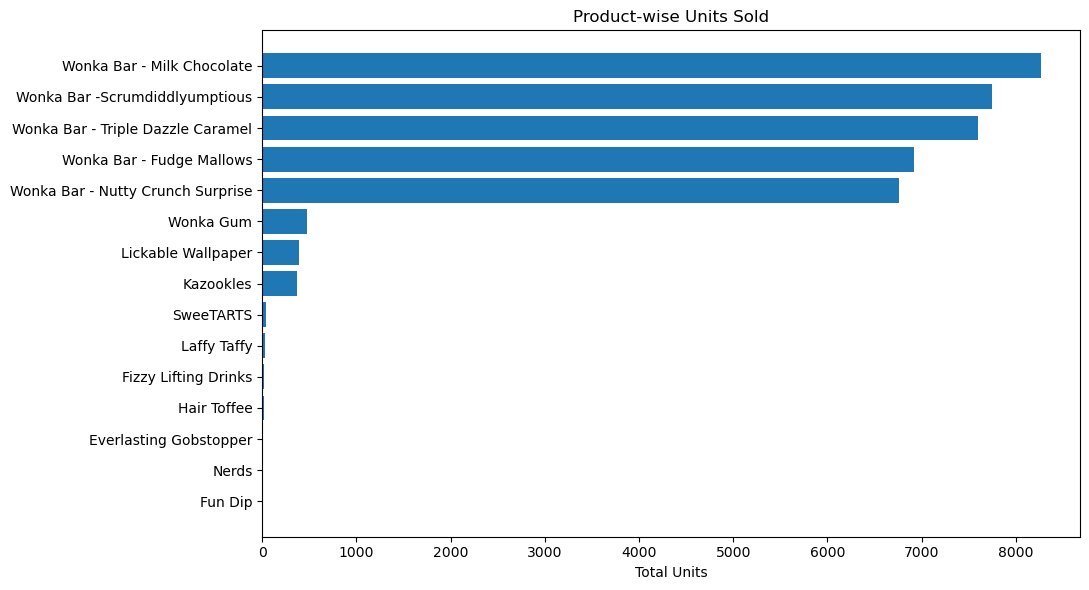

In [39]:
# Compare total units sold across products

data = product_summary.sort_values("Total_Units")

plt.figure(figsize=(11, 6))
plt.barh(data["Product Name"], data["Total_Units"])
plt.title("Product-wise Units Sold")
plt.xlabel("Total Units")
save_chart("eda_13_product_units.png")

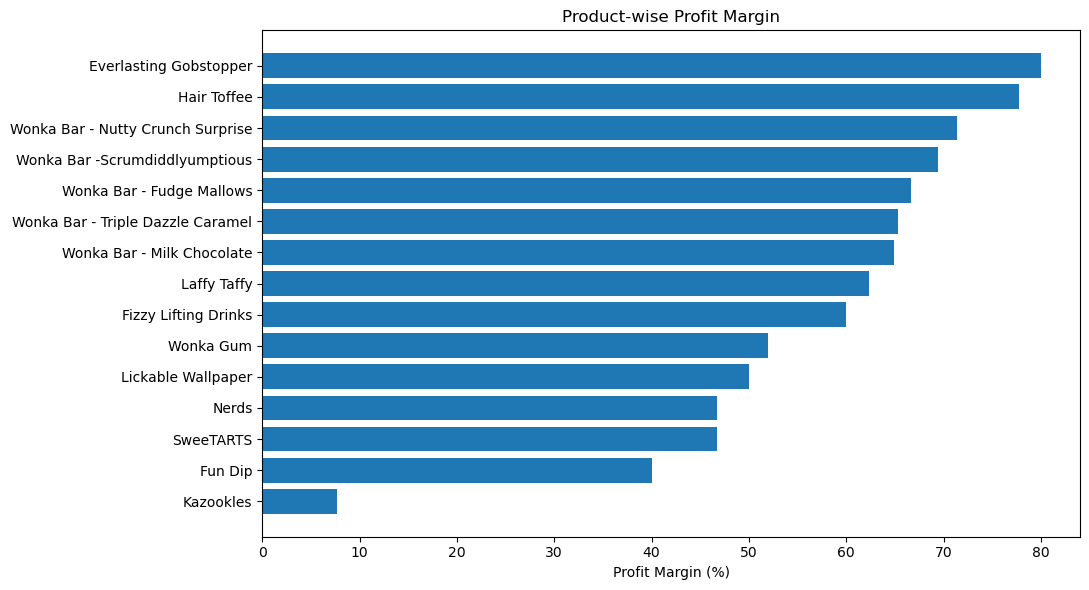

In [41]:
# Compare aggregate gross profit margins across products

data = product_summary.sort_values("Profit_Margin_Pct")

plt.figure(figsize=(11, 6))
plt.barh(data["Product Name"], data["Profit_Margin_Pct"])
plt.title("Product-wise Profit Margin")
plt.xlabel("Profit Margin (%)")
save_chart("eda_14_product_profit_margin.png")

In [43]:
# Rank the top 10 products by total sales

top_10_products = product_summary.nlargest(10, "Total_Sales")

display(top_10_products)

top_10_products.to_csv(
    PROCESSED_FOLDER / "EDA_Top_10_Products.csv",
    index=False
)

,Product Name,Total_Sales,Total_Gross_Profit,Total_Cost,Total_Units,Record_Count,Profit_Margin_Pct
12,Wonka Bar - Triple Dazzle Caramel,28485.00,18610.20,9874.80,7596,2015,65.333333
13,Wonka Bar -Scrumdiddlyumptious,27874.80,19357.50,8517.30,7743,2064,69.444444
10,Wonka Bar - Milk Chocolate,26867.75,17443.37,9424.38,8267,2137,64.923077
9,Wonka Bar - Fudge Mallows,24890.40,16593.60,8296.80,6914,1818,66.666667
11,Wonka Bar - Nutty Crunch Surprise,23574.95,16819.95,6755.00,6755,1810,71.346705
6,Lickable Wallpaper,7860.00,3930.00,3930.00,393,94,50.000000
4,Kazookles,1205.75,92.75,1113.00,371,96,7.692308
14,Wonka Gum,597.50,310.70,286.80,478,120,52.000000
0,Everlasting Gobstopper,130.00,104.00,26.00,13,3,80.000000
1,Fizzy Lifting Drinks,78.75,47.25,31.50,21,6,60.000000


In [45]:
# Rank the bottom 10 products by total sales

bottom_10_products = product_summary.nsmallest(10, "Total_Sales")

display(bottom_10_products)

bottom_10_products.to_csv(
    PROCESSED_FOLDER / "EDA_Bottom_10_Products.csv",
    index=False
)

,Product Name,Total_Sales,Total_Gross_Profit,Total_Cost,Total_Units,Record_Count,Profit_Margin_Pct
2,Fun Dip,12.00,4.80,7.20,8,3,40.000000
7,Nerds,15.00,7.00,8.00,10,4,46.666667
5,Laffy Taffy,53.73,33.48,20.25,27,10,62.311558
8,SweeTARTS,61.50,28.70,32.80,41,10,46.666667
3,Hair Toffee,76.50,59.50,17.00,17,4,77.777778
1,Fizzy Lifting Drinks,78.75,47.25,31.50,21,6,60.000000
0,Everlasting Gobstopper,130.00,104.00,26.00,13,3,80.000000
14,Wonka Gum,597.50,310.70,286.80,478,120,52.000000
4,Kazookles,1205.75,92.75,1113.00,371,96,7.692308
6,Lickable Wallpaper,7860.00,3930.00,3930.00,393,94,50.000000


In [47]:
 #Division and region comparisons
# Division-wise sales

,Division,Total_Sales,Total_Gross_Profit,Total_Cost,Total_Units,Record_Count,Profit_Margin_Pct
0,Chocolate,131692.90,88824.62,42868.28,37275,9844,67.448298
1,Other,9663.25,4333.45,5329.80,1242,310,44.844643
2,Sugar,427.48,284.73,142.75,137,40,66.606625


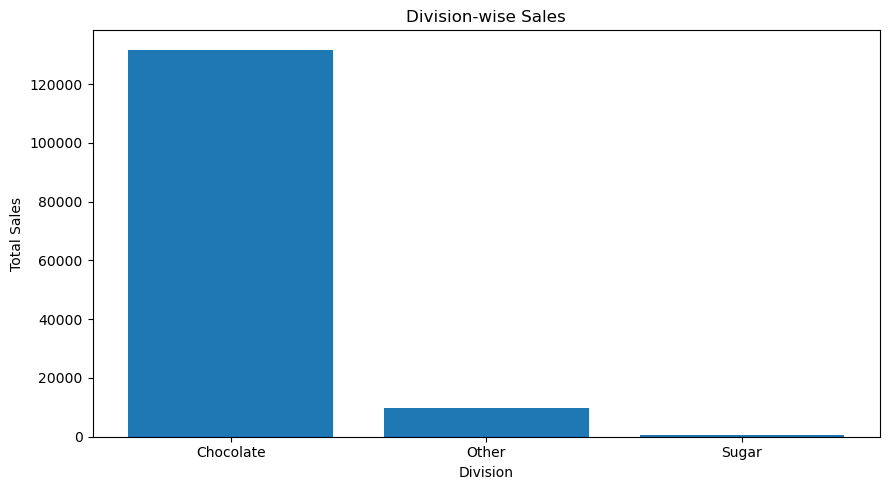

In [49]:
# Compare total sales by division

division_summary = add_profit_margin(
    grouped_summary("Division")
).sort_values("Total_Sales", ascending=False)

display(division_summary)

plt.figure(figsize=(9, 5))
plt.bar(
    division_summary["Division"].astype(str),
    division_summary["Total_Sales"]
)
plt.title("Division-wise Sales")
plt.xlabel("Division")
plt.ylabel("Total Sales")
save_chart("eda_17_division_sales.png")

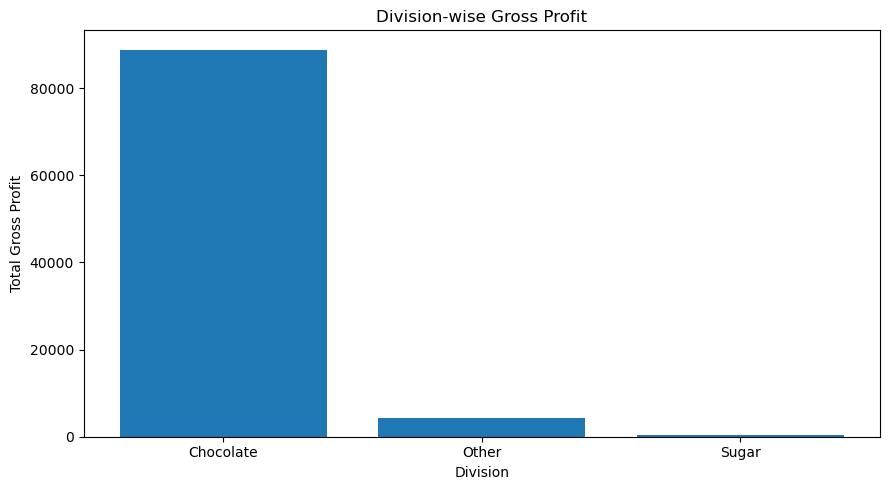

In [51]:
# Compare total gross profit by division

plt.figure(figsize=(9, 5))
plt.bar(
    division_summary["Division"].astype(str),
    division_summary["Total_Gross_Profit"]
)
plt.title("Division-wise Gross Profit")
plt.xlabel("Division")
plt.ylabel("Total Gross Profit")
save_chart("eda_18_division_profit.png")

,Region,Total_Sales,Total_Gross_Profit,Total_Cost,Total_Units,Record_Count,Profit_Margin_Pct
3,Pacific,46301.53,30485.94,15815.59,12466,3253,65.842187
0,Atlantic,41197.24,26973.70,14223.54,11159,2986,65.474532
2,Interior,32037.60,21282.49,10755.11,8820,2335,66.429726
1,Gulf,22247.26,14700.67,7546.59,6209,1620,66.078564


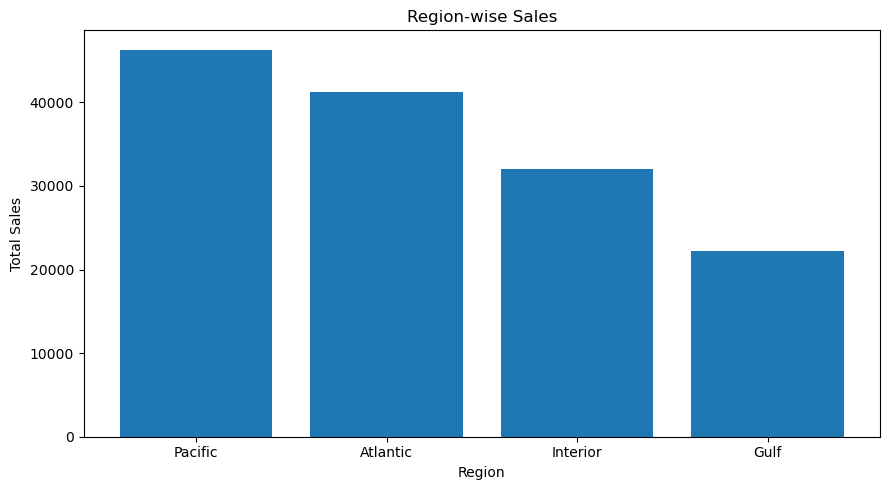

In [55]:
#Region-wise sales

# Compare total sales by region

region_summary = add_profit_margin(
    grouped_summary("Region")
).sort_values("Total_Sales", ascending=False)

display(region_summary)

plt.figure(figsize=(9, 5))
plt.bar(
    region_summary["Region"].astype(str),
    region_summary["Total_Sales"]
)
plt.title("Region-wise Sales")
plt.xlabel("Region")
plt.ylabel("Total Sales")
save_chart("eda_19_region_sales.png")

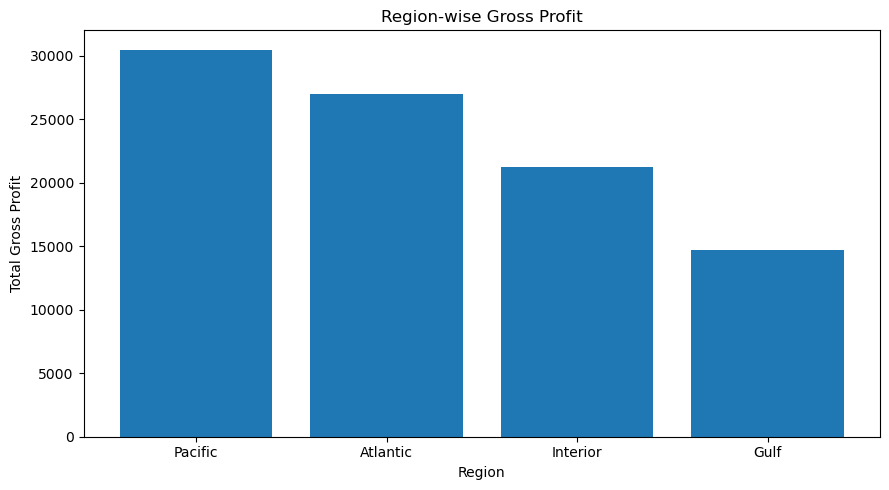

In [57]:
# Compare total gross profit by region

plt.figure(figsize=(9, 5))
plt.bar(
    region_summary["Region"].astype(str),
    region_summary["Total_Gross_Profit"]
)
plt.title("Region-wise Gross Profit")
plt.xlabel("Region")
plt.ylabel("Total Gross Profit")
save_chart("eda_20_region_profit.png")

,State/Province,Total_Sales,Total_Gross_Profit,Total_Cost,Total_Units,Record_Count,Profit_Margin_Pct
5,California,27917.40,18479.42,9437.98,7667,2001,66.193199
34,New York,15541.03,10222.44,5318.59,4224,1128,65.777107
51,Texas,13416.09,8909.53,4506.56,3724,985,66.409289
43,Pennsylvania,8027.03,5225.47,2801.56,2153,587,65.098424
55,Washington,6921.15,4566.64,2354.51,1883,506,65.980942
13,Illinois,6898.96,4557.68,2341.28,1845,492,66.063291
39,Ohio,6768.95,4413.03,2355.92,1759,469,65.195193
10,Florida,4804.02,3207.11,1596.91,1379,383,66.758881
2,Arizona,3587.55,2290.11,1297.44,862,224,63.834929
36,North Carolina,3450.86,2331.16,1119.70,983,249,67.553016


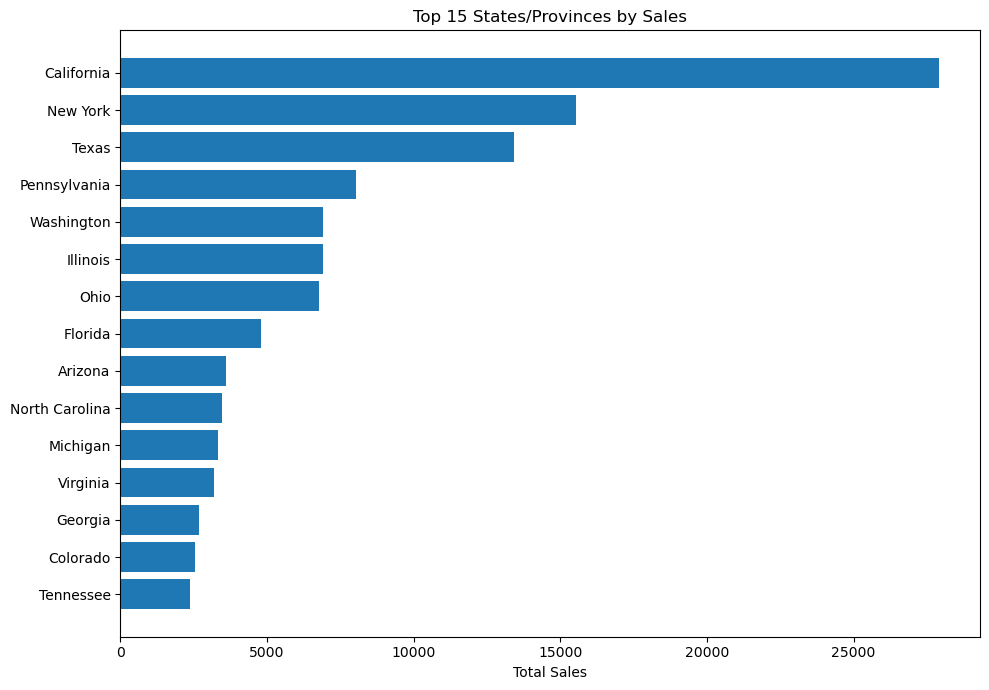

In [59]:
#State, city and customer rankings
#State-wise performance
# Rank states and provinces by sales and gross profit

state_summary = add_profit_margin(
    grouped_summary("State/Province")
).sort_values("Total_Sales", ascending=False)

display(state_summary)

state_summary.to_csv(
    PROCESSED_FOLDER / "EDA_State_Performance.csv",
    index=False
)

top_states = state_summary.head(15).sort_values("Total_Sales")

plt.figure(figsize=(10, 7))
plt.barh(top_states["State/Province"].astype(str), top_states["Total_Sales"])
plt.title("Top 15 States/Provinces by Sales")
plt.xlabel("Total Sales")
save_chart("eda_21_state_performance.png")

In [61]:
# Rank cities by sales and gross profit

city_summary = add_profit_margin(
    grouped_summary("City")
).sort_values("Total_Sales", ascending=False)

display(city_summary.head(20))

city_summary.to_csv(
    PROCESSED_FOLDER / "EDA_City_Performance.csv",
    index=False
)

,City,Total_Sales,Total_Gross_Profit,Total_Cost,Total_Units,Record_Count,Profit_Margin_Pct
335,New York City,12514.90,8240.51,4274.39,3417,915,65.845592
270,Los Angeles,10408.75,6898.61,3510.14,2879,747,66.277027
380,Philadelphia,7415.52,4813.82,2601.70,1981,537,64.915475
446,San Francisco,7018.61,4650.77,2367.84,1935,510,66.263405
460,Seattle,5893.39,3880.68,2012.71,1590,428,65.848009
211,Houston,5429.41,3547.43,1881.98,1466,377,65.337302
82,Chicago,4263.92,2800.58,1463.34,1132,314,65.680876
96,Columbus,3357.39,2159.03,1198.36,836,222,64.306798
472,Springfield,2375.00,1540.12,834.88,649,163,64.847158
445,San Diego,2348.88,1567.52,781.36,670,170,66.734784


In [63]:
# Rank customers by total sales

customer_summary = add_profit_margin(
    grouped_summary("Customer ID")
).sort_values("Total_Sales", ascending=False)

display(customer_summary.head(20))

customer_summary.to_csv(
    PROCESSED_FOLDER / "EDA_Customer_Performance.csv",
    index=False
)

,Customer ID,Total_Sales,Total_Gross_Profit,Total_Cost,Total_Units,Record_Count,Profit_Margin_Pct
2326,131807,454.40,256.60,197.80,63,18,56.470070
1124,115238,380.50,249.30,131.20,110,25,65.519054
1637,122336,352.20,193.44,158.76,39,4,54.923339
4690,164756,304.14,166.42,137.72,35,8,54.718222
1770,124163,247.35,127.95,119.40,19,4,51.728320
4692,164770,232.40,122.50,109.90,19,2,52.710843
1859,125388,216.00,115.00,101.00,19,6,53.240741
4615,163790,208.95,113.53,95.42,31,6,54.333573
4644,164147,204.65,107.25,97.40,16,3,52.406548
2939,140326,202.05,104.85,97.20,15,3,51.893096


In [65]:
#Customer-wise profitability
# Rank customers by total gross profit

customer_profitability = customer_summary.sort_values(
    "Total_Gross_Profit", ascending=False
)

display(customer_profitability.head(20))

customer_profitability.to_csv(
    PROCESSED_FOLDER / "EDA_Customer_Profitability.csv",
    index=False
)

,Customer ID,Total_Sales,Total_Gross_Profit,Total_Cost,Total_Units,Record_Count,Profit_Margin_Pct
2326,131807,454.40,256.60,197.80,63,18,56.470070
1124,115238,380.50,249.30,131.20,110,25,65.519054
1637,122336,352.20,193.44,158.76,39,4,54.923339
4690,164756,304.14,166.42,137.72,35,8,54.718222
2887,139675,202.00,134.40,67.60,60,10,66.534653
3748,151799,197.60,132.52,65.08,58,15,67.064777
1770,124163,247.35,127.95,119.40,19,4,51.728320
9,100111,182.41,125.93,56.48,52,14,69.036785
4692,164770,232.40,122.50,109.90,19,2,52.710843
1429,119508,177.14,122.34,54.80,50,10,69.064017


,Ship Mode,Total_Sales,Total_Gross_Profit,Total_Cost,Total_Units,Record_Count,Profit_Margin_Pct
0,First Class,21319.39,14011.09,7308.30,5724,1548,65.719939
1,Same Day,7113.67,4700.73,2412.94,1975,547,66.080237
2,Second Class,27860.22,18306.52,9553.70,7546,1979,65.708455
3,Standard Class,85490.35,56424.46,29065.89,23409,6120,66.000970


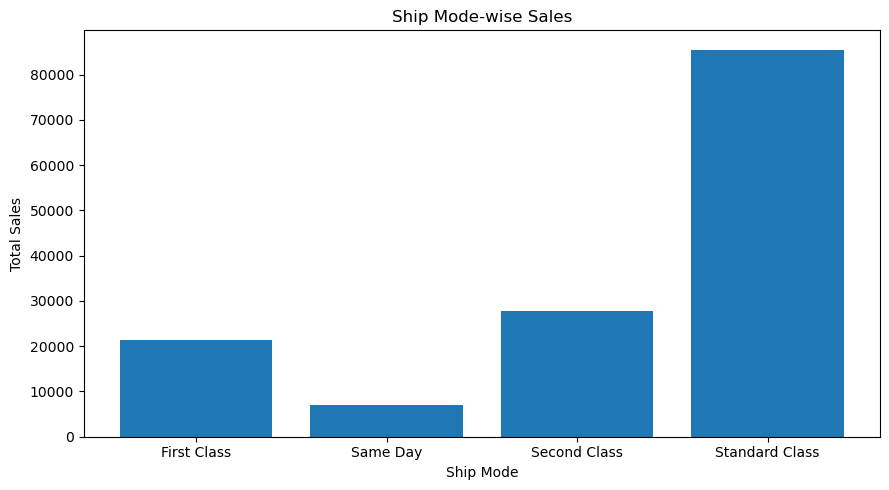

In [67]:
#Ship Mode analysis
# Ship Mode-wise sales
# Compare total sales across shipping modes

shipmode_summary = add_profit_margin(
    grouped_summary("Ship Mode")
)

display(shipmode_summary)

plt.figure(figsize=(9, 5))
plt.bar(
    shipmode_summary["Ship Mode"].astype(str),
    shipmode_summary["Total_Sales"]
)
plt.title("Ship Mode-wise Sales")
plt.xlabel("Ship Mode")
plt.ylabel("Total Sales")
save_chart("eda_25_shipmode_sales.png")

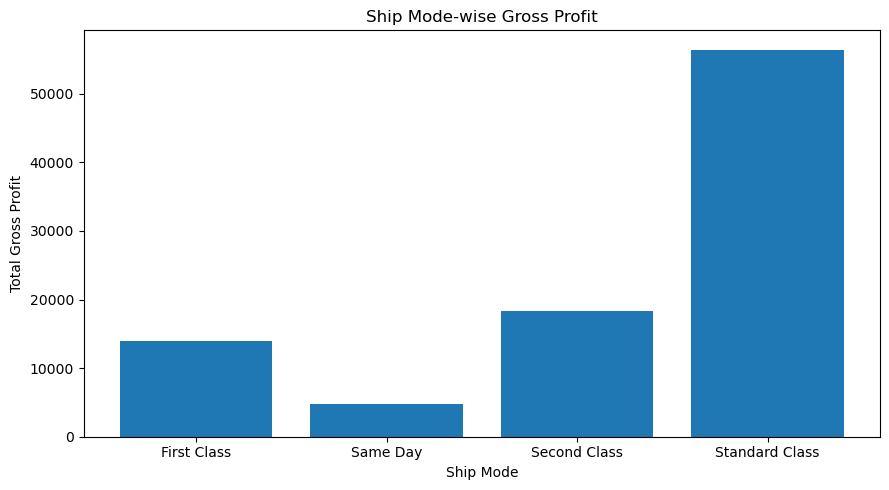

In [69]:
# Compare total gross profit across shipping modes

plt.figure(figsize=(9, 5))
plt.bar(
    shipmode_summary["Ship Mode"].astype(str),
    shipmode_summary["Total_Gross_Profit"]
)
plt.title("Ship Mode-wise Gross Profit")
plt.xlabel("Ship Mode")
plt.ylabel("Total Gross Profit")
save_chart("eda_26_shipmode_profit.png")

,Ship Mode,Average_Lead_Time,Median_Lead_Time,Record_Count
0,First Class,1338.275840,1272.0,1548
1,Same Day,1333.442413,1269.0,547
2,Second Class,1323.845376,1273.0,1979
3,Standard Class,1314.334641,1274.0,6120


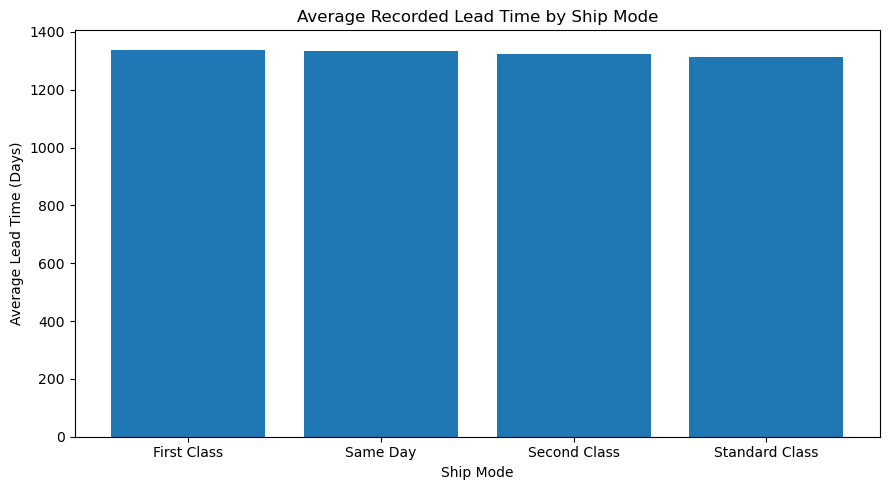

In [71]:
# Compare average and median recorded lead time across shipping modes

shipmode_lead_time = (
    df_eda.groupby("Ship Mode", dropna=False)
    .agg(
        Average_Lead_Time=("Lead_Time_Days", "mean"),
        Median_Lead_Time=("Lead_Time_Days", "median"),
        Record_Count=("Row ID", "count")
    )
    .reset_index()
)

display(shipmode_lead_time)

plt.figure(figsize=(9, 5))
plt.bar(
    shipmode_lead_time["Ship Mode"].astype(str),
    shipmode_lead_time["Average_Lead_Time"]
)
plt.title("Average Recorded Lead Time by Ship Mode")
plt.xlabel("Ship Mode")
plt.ylabel("Average Lead Time (Days)")
save_chart("eda_27_shipmode_lead_time.png")

,Order_Date_Parsed,Total_Sales,Total_Gross_Profit
0,2024-01-01,2093.90,1366.14
1,2024-02-01,1379.87,908.59
2,2024-03-01,4138.90,2671.16
3,2024-04-01,3988.22,2612.81
4,2024-05-01,3951.52,2615.44
5,2024-06-01,3518.76,2330.72
6,2024-07-01,3865.38,2565.26
7,2024-08-01,4477.65,2945.87
8,2024-09-01,7912.10,5206.70
9,2024-10-01,4815.98,3119.46


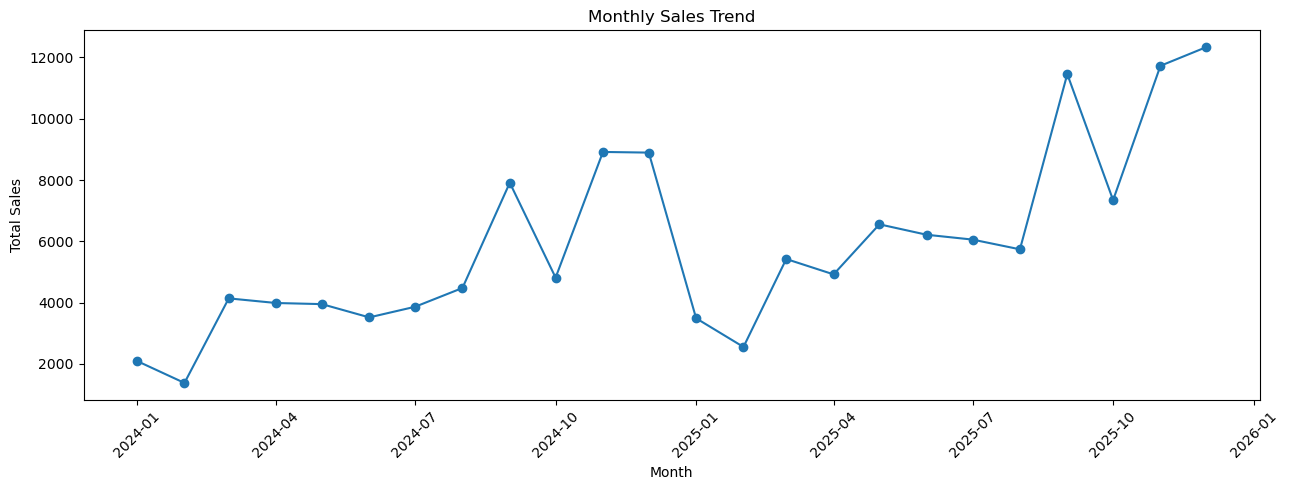

In [73]:
#Time trends
# Monthly sales trends
# Analyse monthly sales trends using parsed order dates

monthly_summary = (
    df_eda.dropna(subset=["Order_Date_Parsed"])
    .set_index("Order_Date_Parsed")
    .resample("MS")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Gross_Profit=("Gross Profit", "sum")
    )
    .reset_index()
)

display(monthly_summary)

plt.figure(figsize=(13, 5))
plt.plot(
    monthly_summary["Order_Date_Parsed"],
    monthly_summary["Total_Sales"],
    marker="o"
)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
save_chart("eda_28_monthly_sales_trend.png")

,Order_Quarter_Period,Total_Sales,Total_Gross_Profit,Quarter
0,2024Q1,7612.67,4945.89,2024Q1
1,2024Q2,11458.50,7558.97,2024Q2
2,2024Q3,16255.13,10717.83,2024Q3
3,2024Q4,22629.90,14928.74,2024Q4
4,2025Q1,11465.99,7594.74,2025Q1
5,2025Q2,17693.05,11719.09,2025Q2
6,2025Q3,23255.37,15277.28,2025Q3
7,2025Q4,31413.02,20700.26,2025Q4


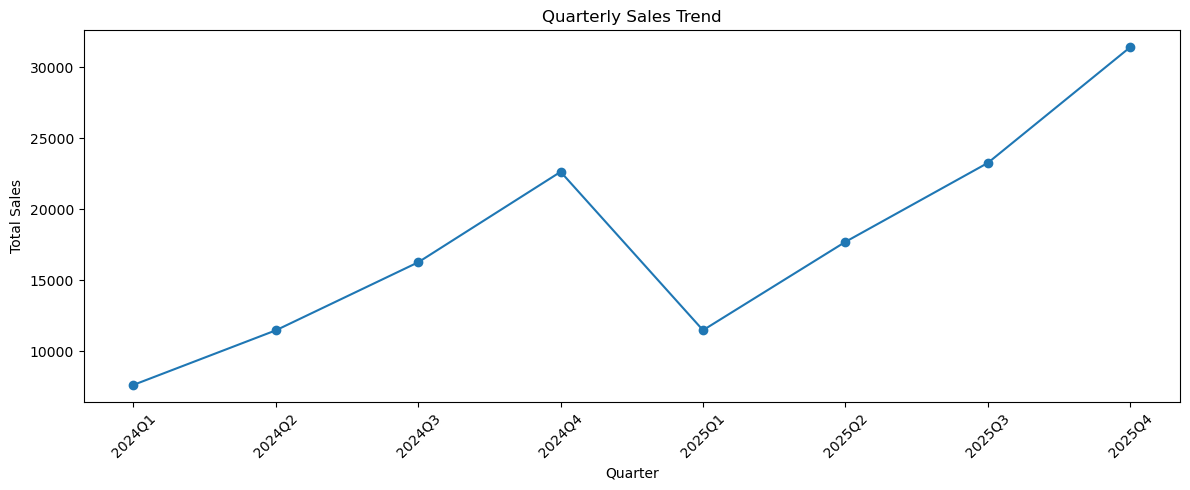

In [75]:
# Analyse quarterly sales trends using parsed order dates

quarterly_summary = (
    df_eda.dropna(subset=["Order_Date_Parsed"])
    .assign(
        Order_Quarter_Period=lambda x:
        x["Order_Date_Parsed"].dt.to_period("Q")
    )
    .groupby("Order_Quarter_Period")
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Gross_Profit=("Gross Profit", "sum")
    )
    .reset_index()
)

quarterly_summary["Quarter"] = (
    quarterly_summary["Order_Quarter_Period"].astype(str)
)

display(quarterly_summary)

plt.figure(figsize=(12, 5))
plt.plot(
    quarterly_summary["Quarter"],
    quarterly_summary["Total_Sales"],
    marker="o"
)
plt.title("Quarterly Sales Trend")
plt.xlabel("Quarter")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
save_chart("eda_29_quarterly_sales_trend.png")

,Order_Year,Total_Sales,Total_Gross_Profit
0,2024,57956.20,38151.43
1,2025,83827.43,55291.37


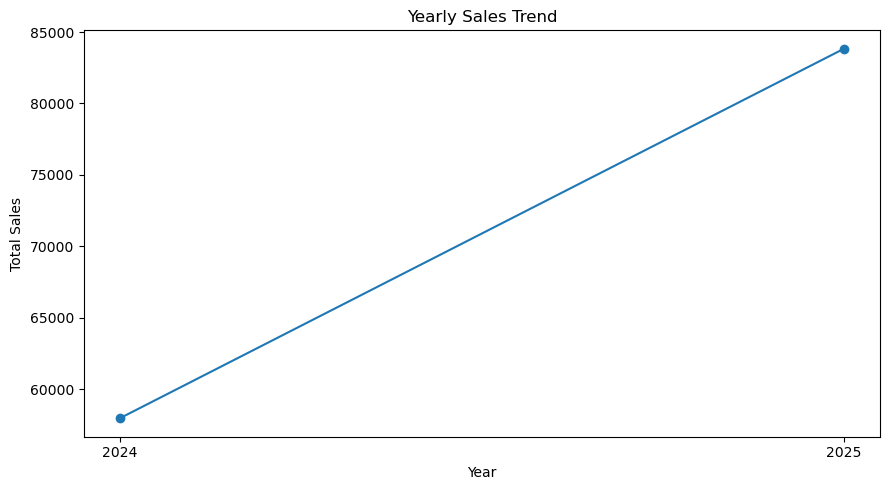

In [77]:
# Analyse yearly sales trends

yearly_summary = (
    df_eda.groupby("Order_Year", dropna=False)
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Gross_Profit=("Gross Profit", "sum")
    )
    .reset_index()
    .sort_values("Order_Year")
)

display(yearly_summary)

plt.figure(figsize=(9, 5))
plt.plot(
    yearly_summary["Order_Year"].astype(str),
    yearly_summary["Total_Sales"],
    marker="o"
)
plt.title("Yearly Sales Trend")
plt.xlabel("Year")
plt.ylabel("Total Sales")
save_chart("eda_30_yearly_sales_trend.png")

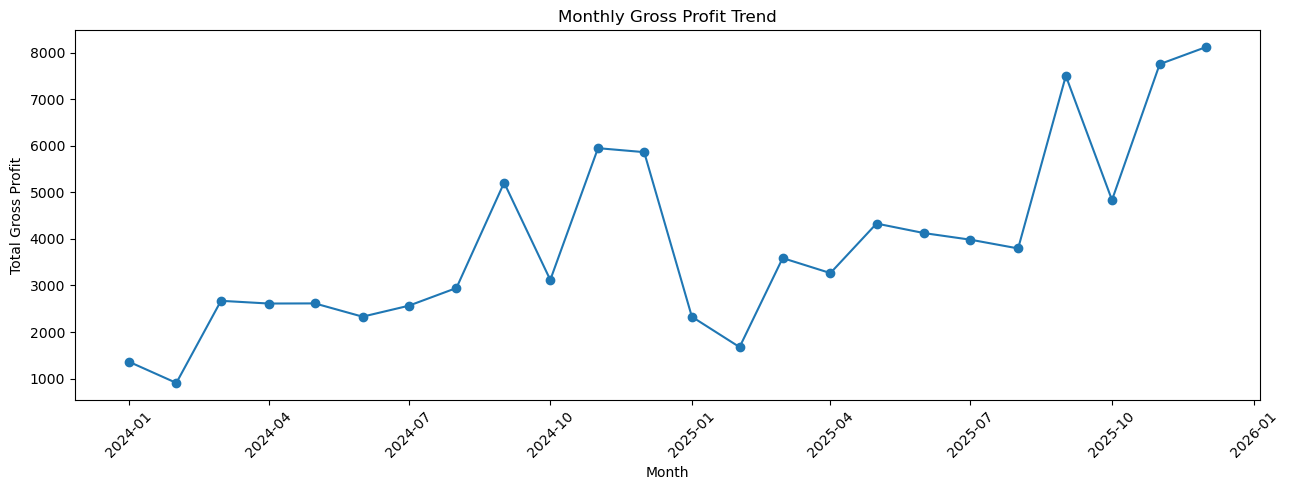

In [79]:
# Analyse monthly gross profit trends

plt.figure(figsize=(13, 5))
plt.plot(
    monthly_summary["Order_Date_Parsed"],
    monthly_summary["Total_Gross_Profit"],
    marker="o"
)
plt.title("Monthly Gross Profit Trend")
plt.xlabel("Month")
plt.ylabel("Total Gross Profit")
plt.xticks(rotation=45)
save_chart("eda_31_monthly_profit_trend.png")

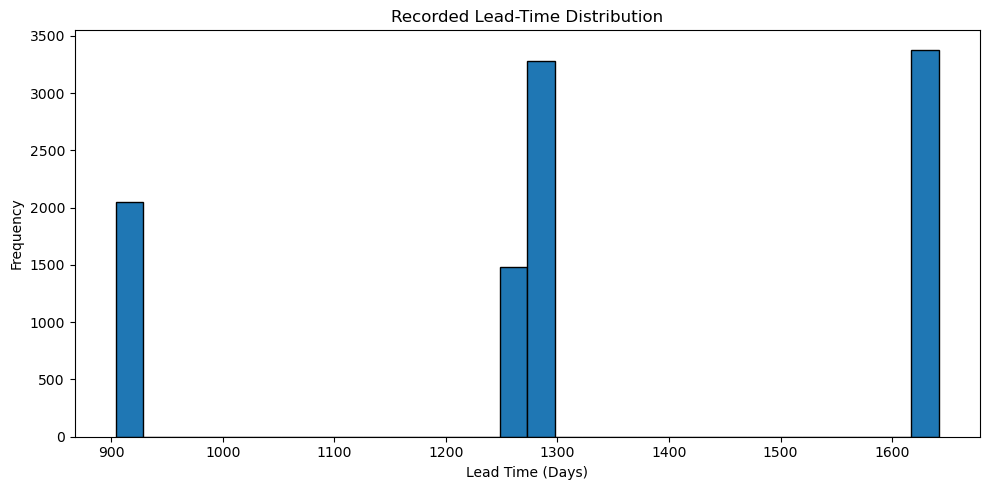

Lead-time statistics:


count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Lead_Time_Days, dtype: float64

In [81]:
#Lead-time comparisons
 #Lead-time distribution
# Visualise lead-time distribution while retaining all observations

plt.figure(figsize=(10, 5))
plt.hist(
    df_eda["Lead_Time_Days"].dropna(),
    bins=30,
    edgecolor="black"
)
plt.title("Recorded Lead-Time Distribution")
plt.xlabel("Lead Time (Days)")
plt.ylabel("Frequency")
save_chart("eda_32_lead_time_distribution.png")

print("Lead-time statistics:")
display(df_eda["Lead_Time_Days"].describe())

,Product Name,Average_Lead_Time,Median_Lead_Time,Record_Count
3,Hair Toffee,1455.250000,1455.0,4
0,Everlasting Gobstopper,1394.666667,1273.0,3
8,SweeTARTS,1383.500000,1274.0,10
5,Laffy Taffy,1383.100000,1275.0,10
6,Lickable Wallpaper,1339.138298,1274.0,94
11,Wonka Bar - Nutty Crunch Surprise,1328.915470,1274.0,1810
12,Wonka Bar - Triple Dazzle Caramel,1325.661042,1274.0,2015
13,Wonka Bar -Scrumdiddlyumptious,1320.641957,1274.0,2064
10,Wonka Bar - Milk Chocolate,1316.764623,1274.0,2137
9,Wonka Bar - Fudge Mallows,1314.242024,1274.0,1818


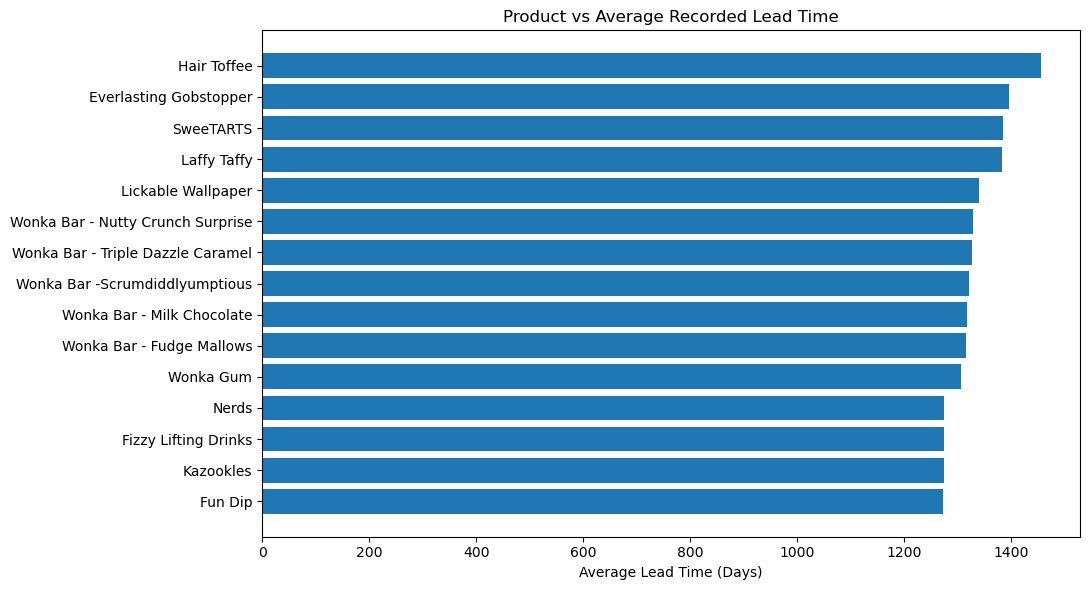

In [83]:
# Compare average recorded lead time across products

product_lead_time = (
    df_eda.groupby("Product Name", dropna=False)
    .agg(
        Average_Lead_Time=("Lead_Time_Days", "mean"),
        Median_Lead_Time=("Lead_Time_Days", "median"),
        Record_Count=("Row ID", "count")
    )
    .reset_index()
    .sort_values("Average_Lead_Time", ascending=False)
)

display(product_lead_time)

plt.figure(figsize=(11, 6))
data = product_lead_time.sort_values("Average_Lead_Time")
plt.barh(data["Product Name"], data["Average_Lead_Time"])
plt.title("Product vs Average Recorded Lead Time")
plt.xlabel("Average Lead Time (Days)")
save_chart("eda_33_product_lead_time.png")

,Region,Average_Lead_Time,Median_Lead_Time,Record_Count
0,Atlantic,1322.745144,1274.0,2986
1,Gulf,1311.374691,1274.0,1620
2,Interior,1323.091221,1274.0,2335
3,Pacific,1322.194897,1274.0,3253


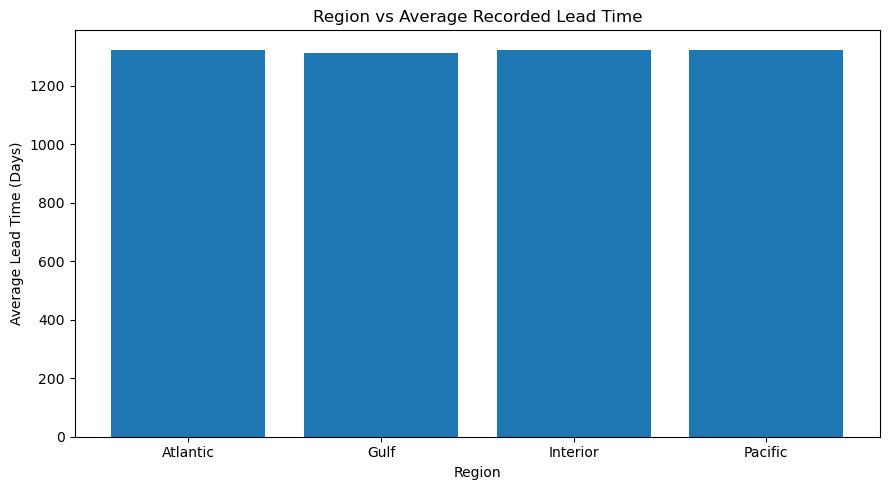

In [85]:
# Compare average recorded lead time across regions

region_lead_time = (
    df_eda.groupby("Region", dropna=False)
    .agg(
        Average_Lead_Time=("Lead_Time_Days", "mean"),
        Median_Lead_Time=("Lead_Time_Days", "median"),
        Record_Count=("Row ID", "count")
    )
    .reset_index()
)

display(region_lead_time)

plt.figure(figsize=(9, 5))
plt.bar(
    region_lead_time["Region"].astype(str),
    region_lead_time["Average_Lead_Time"]
)
plt.title("Region vs Average Recorded Lead Time")
plt.xlabel("Region")
plt.ylabel("Average Lead Time (Days)")
save_chart("eda_34_region_lead_time.png")

,Division,Average_Lead_Time,Median_Lead_Time,Record_Count
0,Chocolate,1321.166904,1274.0,9844
1,Other,1306.029032,1273.0,310
2,Sugar,1355.650000,1274.5,40


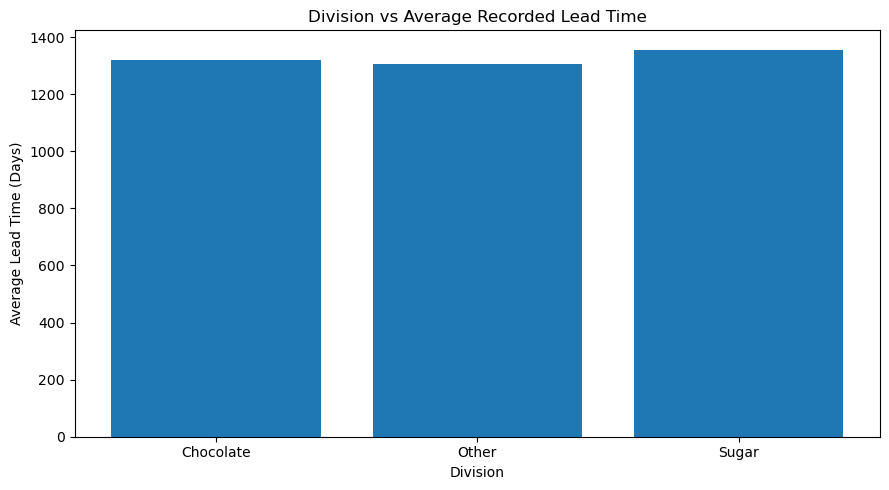

In [87]:
# Compare average recorded lead time across divisions

division_lead_time = (
    df_eda.groupby("Division", dropna=False)
    .agg(
        Average_Lead_Time=("Lead_Time_Days", "mean"),
        Median_Lead_Time=("Lead_Time_Days", "median"),
        Record_Count=("Row ID", "count")
    )
    .reset_index()
)

display(division_lead_time)

plt.figure(figsize=(9, 5))
plt.bar(
    division_lead_time["Division"].astype(str),
    division_lead_time["Average_Lead_Time"]
)
plt.title("Division vs Average Recorded Lead Time")
plt.xlabel("Division")
plt.ylabel("Average Lead Time (Days)")
save_chart("eda_35_division_lead_time.png")

Region,Atlantic,Gulf,Interior,Pacific
Product Name,,,,
Everlasting Gobstopper,0.00,40.00,30.00,60.00
Fizzy Lifting Drinks,33.75,15.00,18.75,11.25
Fun Dip,6.00,1.50,4.50,0.00
Hair Toffee,22.50,9.00,0.00,45.00
Kazookles,484.25,253.50,126.75,341.25
Laffy Taffy,27.86,21.89,1.99,1.99
Lickable Wallpaper,2780.00,740.00,1420.00,2920.00
Nerds,15.00,0.00,0.00,0.00
SweeTARTS,36.00,0.00,19.50,6.00


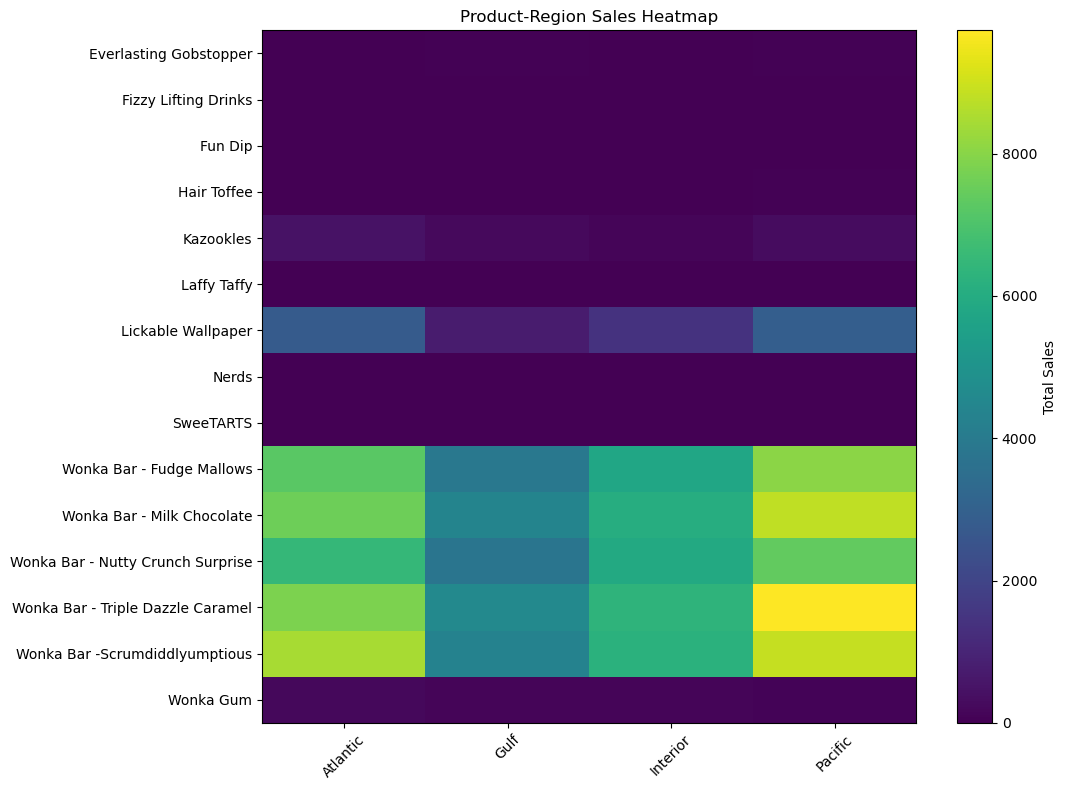

In [89]:
#Relationship and correlation analysis
#Product-region combinations heatmap
# Create a product-region sales matrix for heatmap analysis

product_region_matrix = pd.pivot_table(
    df_eda,
    index="Product Name",
    columns="Region",
    values="Sales",
    aggfunc="sum",
    fill_value=0
)

display(product_region_matrix)

plt.figure(figsize=(11, 8))
plt.imshow(product_region_matrix, aspect="auto")
plt.colorbar(label="Total Sales")
plt.xticks(
    range(len(product_region_matrix.columns)),
    product_region_matrix.columns,
    rotation=45
)
plt.yticks(
    range(len(product_region_matrix.index)),
    product_region_matrix.index
)
plt.title("Product-Region Sales Heatmap")
save_chart("eda_36_product_region_heatmap.png")

product_region_matrix.to_csv(
    PROCESSED_FOLDER / "EDA_Product_Region_Heatmap_Data.csv"
)

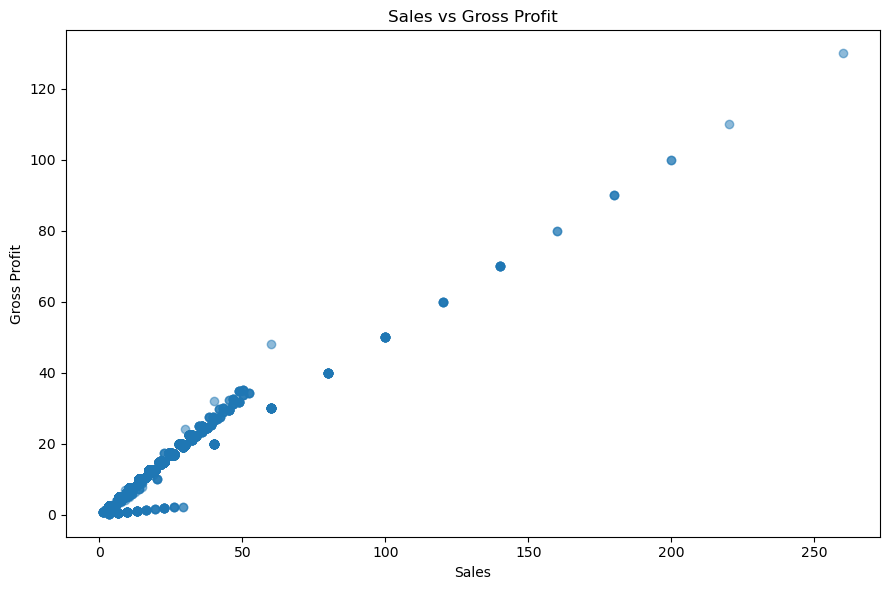

Sales-Gross Profit correlation: 0.9764035538431601


In [91]:
#Sales and gross profit relationship
# Examine the relationship between sales and gross profit

plt.figure(figsize=(9, 6))
plt.scatter(
    df_eda["Sales"],
    df_eda["Gross Profit"],
    alpha=0.5
)
plt.title("Sales vs Gross Profit")
plt.xlabel("Sales")
plt.ylabel("Gross Profit")
save_chart("eda_37_sales_profit_scatterplot.png")

sales_profit_correlation = df_eda[
    ["Sales", "Gross Profit"]
].corr().iloc[0, 1]

print("Sales-Gross Profit correlation:", sales_profit_correlation)

,Sales,Gross Profit,Cost,Units,Lead_Time_Days,Profit_Margin_Pct,Sales_Per_Unit,Cost_Per_Unit,Profit_Per_Unit
Sales,1.000000,0.976404,0.958986,0.729347,-0.005438,-0.111106,0.602697,0.584095,0.573643
Gross Profit,0.976404,1.000000,0.875144,0.815820,-0.003305,0.036781,0.495099,0.444475,0.509454
Cost,0.958986,0.875144,1.000000,0.563344,-0.007846,-0.297219,0.700539,0.725310,0.616602
Units,0.729347,0.815820,0.563344,1.000000,-0.006702,-0.013689,0.014530,0.017348,0.010298
Lead_Time_Days,-0.005438,-0.003305,-0.007846,-0.006702,1.000000,0.018917,0.008578,0.002608,0.014334
Profit_Margin_Pct,-0.111106,0.036781,-0.297219,-0.013689,0.018917,1.000000,-0.166682,-0.418713,0.119464
Sales_Per_Unit,0.602697,0.495099,0.700539,0.014530,0.008578,-0.166682,1.000000,0.963816,0.957549
Cost_Per_Unit,0.584095,0.444475,0.725310,0.017348,0.002608,-0.418713,0.963816,1.000000,0.846057
Profit_Per_Unit,0.573643,0.509454,0.616602,0.010298,0.014334,0.119464,0.957549,0.846057,1.000000


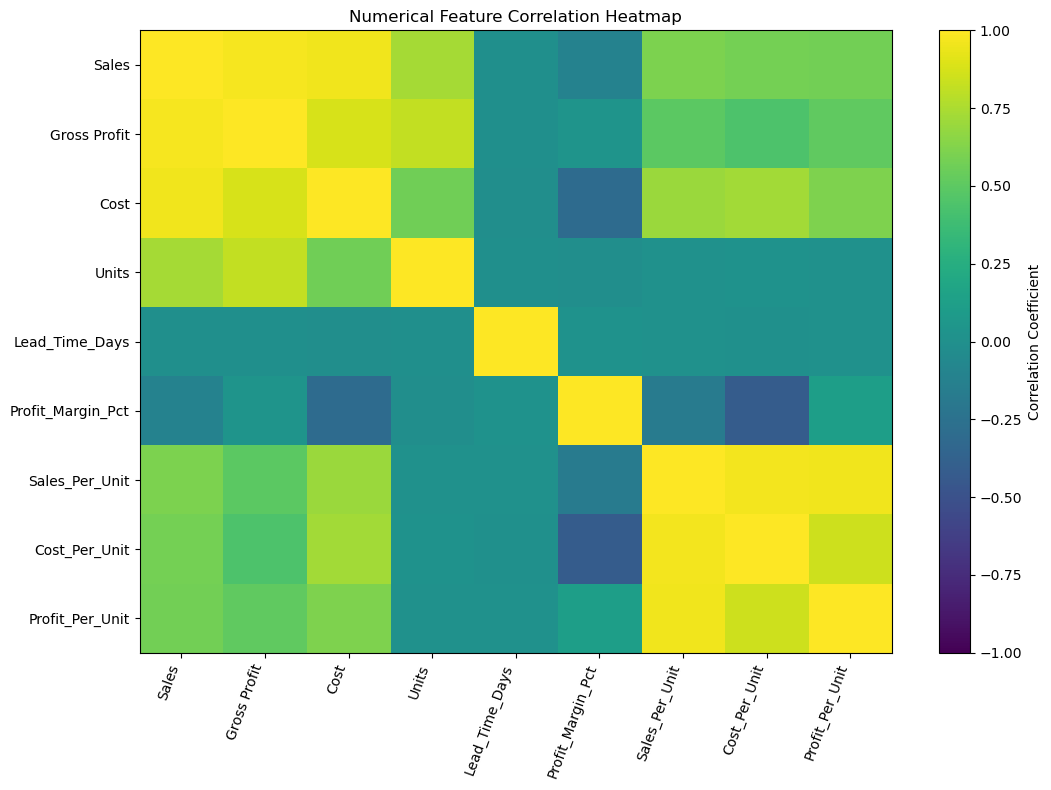

In [93]:
#Correlation analysis heatmap
# Calculate and visualise correlations among numerical features

correlation_columns = [
    "Sales", "Gross Profit", "Cost", "Units",
    "Lead_Time_Days", "Profit_Margin_Pct",
    "Sales_Per_Unit", "Cost_Per_Unit", "Profit_Per_Unit"
]

correlation_matrix = df_eda[correlation_columns].corr()

display(correlation_matrix)

plt.figure(figsize=(11, 8))
plt.imshow(
    correlation_matrix,
    vmin=-1,
    vmax=1,
    aspect="auto"
)
plt.colorbar(label="Correlation Coefficient")
plt.xticks(
    range(len(correlation_columns)),
    correlation_columns,
    rotation=70,
    ha="right"
)
plt.yticks(
    range(len(correlation_columns)),
    correlation_columns
)
plt.title("Numerical Feature Correlation Heatmap")
save_chart("eda_38_correlation_heatmap.png")

correlation_matrix.to_csv(
    PROCESSED_FOLDER / "EDA_Correlation_Matrix.csv"
)

In [95]:
#Findings and report export
#EDA findings
#This cell creates findings from the actual calculated summaries. These are descriptive observations, not claims about causes.
# Generate written EDA findings from the calculated dataset summaries

overall_margin = (
    df_eda["Gross Profit"].sum() / df_eda["Sales"].sum() * 100
    if df_eda["Sales"].sum() != 0 else np.nan
)

top_product_row = product_summary.sort_values(
    "Total_Sales", ascending=False
).iloc[0]

bottom_product_row = product_summary.sort_values(
    "Total_Sales", ascending=True
).iloc[0]

top_region_row = region_summary.sort_values(
    "Total_Sales", ascending=False
).iloc[0]

top_division_row = division_summary.sort_values(
    "Total_Sales", ascending=False
).iloc[0]

top_customer_row = customer_summary.sort_values(
    "Total_Sales", ascending=False
).iloc[0]

top_profit_customer_row = customer_profitability.iloc[0]

top_shipmode_row = shipmode_summary.sort_values(
    "Total_Sales", ascending=False
).iloc[0]

findings = [
    f"Total sales across all records were {df_eda['Sales'].sum():,.2f}.",
    f"Total gross profit was {df_eda['Gross Profit'].sum():,.2f}.",
    f"Total cost was {df_eda['Cost'].sum():,.2f}.",
    f"Total units sold were {df_eda['Units'].sum():,.0f}.",
    f"Average sales per row were {df_eda['Sales'].mean():,.2f}.",
    f"Average gross profit per row was {df_eda['Gross Profit'].mean():,.2f}.",
    f"Overall gross profit margin was {overall_margin:.2f}%.",
    f"The highest-sales product was {top_product_row['Product Name']}, with sales of {top_product_row['Total_Sales']:,.2f}.",
    f"The lowest-sales product was {bottom_product_row['Product Name']}, with sales of {bottom_product_row['Total_Sales']:,.2f}.",
    f"The highest-sales region was {top_region_row['Region']}, with sales of {top_region_row['Total_Sales']:,.2f}.",
    f"The highest-sales division was {top_division_row['Division']}, with sales of {top_division_row['Total_Sales']:,.2f}.",
    f"The highest-sales customer ID was {top_customer_row['Customer ID']}, with sales of {top_customer_row['Total_Sales']:,.2f}.",
    f"The highest-gross-profit customer ID was {top_profit_customer_row['Customer ID']}, with gross profit of {top_profit_customer_row['Total_Gross_Profit']:,.2f}.",
    f"The highest-sales ship mode was {top_shipmode_row['Ship Mode']}, with sales of {top_shipmode_row['Total_Sales']:,.2f}.",
    f"Median recorded lead time was {df_eda['Lead_Time_Days'].median():,.2f} days.",
    f"Sales and gross profit correlation was {df_eda[['Sales', 'Gross Profit']].corr().iloc[0, 1]:.4f}."
]

eda_findings = pd.DataFrame({
    "Finding_Number": range(1, len(findings) + 1),
    "EDA_Finding": findings
})

display(eda_findings)

eda_findings.to_csv(
    PROCESSED_FOLDER / "EDA_Findings.csv",
    index=False
)

# Save a readable text version of the findings
findings_path = REPORT_FOLDER / "EDA_Findings.txt"

with open(findings_path, "w", encoding="utf-8") as file:
    file.write("NASSAU CANDY DISTRIBUTOR — EDA FINDINGS\n")
    file.write("=" * 55 + "\n\n")

    for number, finding in enumerate(findings, start=1):
        file.write(f"{number}. {finding}\n\n")

print("EDA findings saved:", findings_path)

,Finding_Number,EDA_Finding
0,1,"Total sales across all records were 141,783.63."
1,2,"Total gross profit was 93,442.80."
2,3,"Total cost was 48,340.83."
3,4,"Total units sold were 38,654."
4,5,Average sales per row were 13.91.
5,6,Average gross profit per row was 9.17.
6,7,Overall gross profit margin was 65.91%.
7,8,The highest-sales product was Wonka Bar - Trip...
8,9,"The lowest-sales product was Fun Dip, with sal..."
9,10,"The highest-sales region was Pacific, with sal..."


EDA findings saved: C:\Users\hp\Nassau_Candy_Final_Submission\reports\EDA_Findings.txt


In [97]:
#Export EDA report to Excel, CSV and charts
#This cell creates a multi-sheet Excel workbook, exports the main summaries as CSV files, and creates a list of saved chart files.
# Export the complete EDA report to Excel, CSV, and chart inventory

kpi_report = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Gross Profit",
        "Total Cost",
        "Total Units Sold",
        "Average Sales per Row",
        "Average Gross Profit per Row",
        "Overall Profit Margin (%)"
    ],
    "Value": [
        df_eda["Sales"].sum(),
        df_eda["Gross Profit"].sum(),
        df_eda["Cost"].sum(),
        df_eda["Units"].sum(),
        df_eda["Sales"].mean(),
        df_eda["Gross Profit"].mean(),
        overall_margin
    ]
})

# Collect available analysis outputs into one Excel workbook
eda_sheets = {
    "KPIs": kpi_report,
    "Product": product_summary,
    "Top_10_Products": top_10_products,
    "Bottom_10_Products": bottom_10_products,
    "Division": division_summary,
    "Region": region_summary,
    "State": state_summary,
    "City": city_summary,
    "Customer": customer_summary,
    "Customer_Profit": customer_profitability,
    "Ship_Mode": shipmode_summary,
    "Ship_Lead_Time": shipmode_lead_time,
    "Monthly": monthly_summary,
    "Quarterly": quarterly_summary,
    "Yearly": yearly_summary,
    "Product_Lead_Time": product_lead_time,
    "Region_Lead_Time": region_lead_time,
    "Division_Lead_Time": division_lead_time,
    "Profit_Margin": product_summary[
        ["Product Name", "Total_Sales", "Total_Gross_Profit", "Profit_Margin_Pct"]
    ],
    "Correlation": correlation_matrix.reset_index(),
    "Findings": eda_findings
}

EXCEL_PATH = REPORT_FOLDER / "Nassau_Candy_EDA_Report.xlsx"

with pd.ExcelWriter(EXCEL_PATH, engine="openpyxl") as writer:
    for sheet_name, report_df in eda_sheets.items():
        report_df.to_excel(
            writer,
            sheet_name=sheet_name[:31],
            index=False
        )

# Export selected key reports as separate CSV files
csv_reports = {
    "EDA_KPI_Summary.csv": kpi_report,
    "EDA_Product_Summary.csv": product_summary,
    "EDA_Division_Summary.csv": division_summary,
    "EDA_Region_Summary.csv": region_summary,
    "EDA_State_Summary.csv": state_summary,
    "EDA_City_Summary.csv": city_summary,
    "EDA_Customer_Summary.csv": customer_summary,
    "EDA_Ship_Mode_Summary.csv": shipmode_summary,
    "EDA_Monthly_Summary.csv": monthly_summary,
    "EDA_Quarterly_Summary.csv": quarterly_summary,
    "EDA_Yearly_Summary.csv": yearly_summary,
    "EDA_Findings.csv": eda_findings
}

for filename, report_df in csv_reports.items():
    report_df.to_csv(
        PROCESSED_FOLDER / filename,
        index=False
    )

# Create an inventory of generated charts
chart_files = sorted(FIGURES_FOLDER.glob("eda_*.png"))

chart_inventory = pd.DataFrame({
    "Chart_File": [path.name for path in chart_files],
    "Full_Path": [str(path) for path in chart_files]
})

chart_inventory.to_csv(
    REPORT_FOLDER / "EDA_Chart_Inventory.csv",
    index=False
)

print("EDA Excel report exported:", EXCEL_PATH.exists())
print("Excel report:", EXCEL_PATH)
print("CSV reports exported:", len(csv_reports))
print("Charts found:", len(chart_inventory))
print("Chart inventory:", REPORT_FOLDER / "EDA_Chart_Inventory.csv")

display(chart_inventory)

EDA Excel report exported: True
Excel report: C:\Users\hp\Nassau_Candy_Final_Submission\reports\Nassau_Candy_EDA_Report.xlsx
CSV reports exported: 12
Charts found: 27
Chart inventory: C:\Users\hp\Nassau_Candy_Final_Submission\reports\EDA_Chart_Inventory.csv


,Chart_File,Full_Path
0,eda_07_sales_distribution.png,C:\Users\hp\Nassau_Candy_Final_Submission\repo...
1,eda_08_profit_distribution.png,C:\Users\hp\Nassau_Candy_Final_Submission\repo...
2,eda_09_cost_distribution.png,C:\Users\hp\Nassau_Candy_Final_Submission\repo...
3,eda_10_units_distribution.png,C:\Users\hp\Nassau_Candy_Final_Submission\repo...
4,eda_11_product_sales.png,C:\Users\hp\Nassau_Candy_Final_Submission\repo...
5,eda_12_product_profit.png,C:\Users\hp\Nassau_Candy_Final_Submission\repo...
6,eda_13_product_units.png,C:\Users\hp\Nassau_Candy_Final_Submission\repo...
7,eda_14_product_profit_margin.png,C:\Users\hp\Nassau_Candy_Final_Submission\repo...
8,eda_17_division_sales.png,C:\Users\hp\Nassau_Candy_Final_Submission\repo...
9,eda_18_division_profit.png,C:\Users\hp\Nassau_Candy_Final_Submission\repo...


In [99]:
# integrity verification
#Run this after all 40 tasks. It confirms that the EDA work did not change the original data or remove any records.
# Verify EDA row preservation and original dataset integrity

RAW_CSV_PATH = (
    PROJECT_ROOT / "data" / "raw"
    / "Nassau Candy Distributor.csv"
)

df_original_check = pd.read_csv(RAW_CSV_PATH)

integrity_results = {
    "Original CSV exists": RAW_CSV_PATH.exists(),
    "EDA row count preserved": len(df_eda) == len(df_original_check),
    "Original 18 columns retained": all(
        column in df_eda.columns for column in original_columns
    ),
    "Original column values unchanged": df_eda[
        original_columns
    ].equals(df_original_check[original_columns]),
    "No rows removed": len(df_eda) == 10194,
    "EDA Excel report exists": EXCEL_PATH.exists(),
    "EDA findings report exists": findings_path.exists()
}

integrity_report = pd.DataFrame(
    list(integrity_results.items()),
    columns=["Integrity_Check", "Result"]
)

display(integrity_report)

print(
    "All integrity checks passed:",
    all(integrity_results.values())
)

assert all(integrity_results.values()), (
    "One or more EDA integrity checks failed."
)

,Integrity_Check,Result
0,Original CSV exists,True
1,EDA row count preserved,True
2,Original 18 columns retained,True
3,Original column values unchanged,True
4,No rows removed,True
5,EDA Excel report exists,True
6,EDA findings report exists,True


All integrity checks passed: True
